# Assignment 2 — Q1: base-case models R, I and C

本 Notebook 完成 suggested steps 1–3。先阅读 `PLAN_zh.md`，再运行模型。模型源代码在 `main.py`，实验与独立求解检查在 `base_case.py`。

**要回答的问题**：个人合同能减少多少拥塞？社区共享容量后，拥塞与总成本如何变化？

展示：24 小时进口与容量图、关键指标表、负荷/电池/PV响应。完整 Q1 仍需要合同敏感性与成员结算分析。

资料：A2 pp.4–5、8（Tables 8–9）、10–11；教师 A1 Solutions §§2.1、3.2；教师对应线性不适成本和电池代码；本组 A1 报告与实现。

In [1]:
from pathlib import Path
import sys
ROOT = Path.cwd()
if not (ROOT / 'base_case.py').exists():
    ROOT = ROOT / 'Assignment2' / 'Q1_models'
if not (ROOT / 'base_case.py').exists():
    raise RuntimeError('Open this notebook in Q1_models or from the course workspace root.')
sys.path.insert(0, str(ROOT.resolve()))
import pandas as pd
from IPython.display import display, Image, Markdown
from base_case import run_base_case
from main import load_data
data = load_data(ROOT / 'data')
display(pd.DataFrame([dict(member=a.id, cL=a.cL, daily_min_kWh=a.minimum,
    PV_kW=max(a.pv), battery_kWh=a.capacity, initial_SOC_kWh=a.initial)
    for a in data.members]).rename(columns={'PV_kW':'peak_available_PV_kWh'}))

,member,cL,daily_min_kWh,peak_available_PV_kWh,battery_kWh,initial_SOC_kWh
0,C1,0.25,16.17,0.00,0.0,0.0
1,C1_PV,0.25,16.17,2.55,0.0,0.0
2,C1_B,0.25,16.17,0.00,2.0,1.0
3,C1_PVB,0.25,16.17,2.55,2.0,1.0
4,C2,0.50,16.17,0.00,0.0,0.0
5,C2_PV,0.50,16.17,2.55,0.0,0.0
6,C2_B,0.50,16.17,0.00,2.0,1.0
7,C2_PVB,0.50,16.17,2.55,2.0,1.0
8,C3,1.00,16.17,0.00,0.0,0.0
9,C3_PV,1.00,16.17,2.55,0.0,0.0


## 共同约束与模型选择

每个成员的净需求 $n_{it}=L_{it}+ch_{it}-P_{it}-dis_{it}$。

$$\max(0,L^{ref}_{it}-1)\le L_{it}\le\min(3,L^{ref}_{it}+1),\quad
\sum_t L_{it}\ge\sum_t L^{ref}_{it}.$$

偏离拆分 $L_{it}-L^{ref}_{it}=d^+_{it}-d^-_{it}$、$d^+_{it},d^-_{it}\ge0$，不适成本 $c_i^L(d^+_{it}+d^-_{it})$。PV 上限为输入可用量；可弃光，实际产量支付边际成本。

$$e_{it}=e_{i,t-1}+\eta^{ch}ch_{it}-dis_{it}/\eta^{dis},\qquad e_{i,23}\ge e_i^{init}.$$

SOC、充放电均有输入容量边界。1 h 时间步：小时流量为 kWh，电池功率与容量上限为 kW，数值上乘以 1 h。

三种情形均使用正文的日末 SOC 下限，与教师参考一致。循环 SOC 只保留为诊断选项；基准末库存取等不代表两个模型相同。A2 使用线性不适成本，因此三者都是 LP；可行有界时强对偶成立，KKT 为最优性条件。基准检查互斥，无需引入整数变量。

## R、I、C：一套类，改变计量和合同参数

令 $D=\sum_{it}(c_i^L(d^+_{it}+d^-_{it})+c_i^{PV}P_{it})$。

**R**：$I_{it}-E_{it}=n_{it}$；最小化 $D+\sum_{it}[(p_t+\tau^{imp})I_{it}-(p_t-\tau^{exp})E_{it}]$。无跨成员约束，求和求解等价各自独立求解。

**I**：由 R 求出固定份额 $\kappa_i=[\sum_t n^R_{it}]_+/\sum_j[\sum_t n^R_{jt}]_+$。使用折扣后费率，增加 $x_{it}\ge I_{it}-\kappa_i cap_t$、$x_{it}\ge0$ 及罚金 $\alpha\sum_{it}x_{it}$。

**C**：用公共电表 $P_t^{imp}-P_t^{exp}=\sum_i n_{it}$ 替代各自计量。最小化
$$J^C=D+\sum_t[(p_t+(1-\beta)\tau^{imp})P_t^{imp}
-(p_t-(1-\beta)\tau^{exp})P_t^{exp}+\alpha x_t],$$
其中 $x_t\ge P_t^{imp}-cap_t$、$x_t\ge0$。程序直接最小化 $J$；另外输出 $W=-J$ 方便后续福利比较。

基准 $\beta=0.75$、$\alpha=10$ DKK/kWh、$cap_t=9.39$ kW（使用文件精确值）。按官方 JSON/README，折扣用于所有计量流量，超限另加罚金；题目“below cap”措辞的歧义记录在规划中。

**先定义指标**：R/I 的馈线进口为各成员 gross import 之和；C 为公共电表进口。$E^{exc}=\sum_t[import_t-cap_t]_+$ kWh；超限小时按 $2\times10^{-6}$ 容差计数。I 的收费超额与馈线超限分别记录。收益 $J^R-J$，正值为整体节省。

In [2]:
data, models, results, validation = run_base_case()
fields = ['variant','total_cost_DKK','gain_vs_R_DKK','peak_import_kW',
          'feeder_exceedance_kWh','hours_above_cap','charged_exceedance_kWh','penalty_DKK']
table = pd.DataFrame(validation['results']).set_index('variant')
display(table[[f for f in fields if f != 'variant']].round(6))

Set parameter Username
Set parameter LicenseID to value 2860068
Academic license - for non-commercial use only - expires 2027-09-03
All base-case checks passed, including independent HiGHS solutions.
R: cost=398.241694 DKK; peak=27.600000 kW; exceedance=66.702105 kWh; hours=9
I: cost=480.669430 DKK; peak=11.082393 kW; exceedance=4.288039 kWh; hours=3
C: cost=372.162434 DKK; peak=9.390000 kW; exceedance=0.000000 kWh; hours=0


,total_cost_DKK,gain_vs_R_DKK,peak_import_kW,feeder_exceedance_kWh,hours_above_cap,charged_exceedance_kWh,penalty_DKK
variant,,,,,,,
R,398.241694,0.000000,27.600000,66.702105,9,0.000000,0.000000
I,480.669430,-82.427736,11.082393,4.288039,3,4.288039,42.880393
C,372.162434,26.079260,9.390000,0.000000,0,0.000000,0.000000


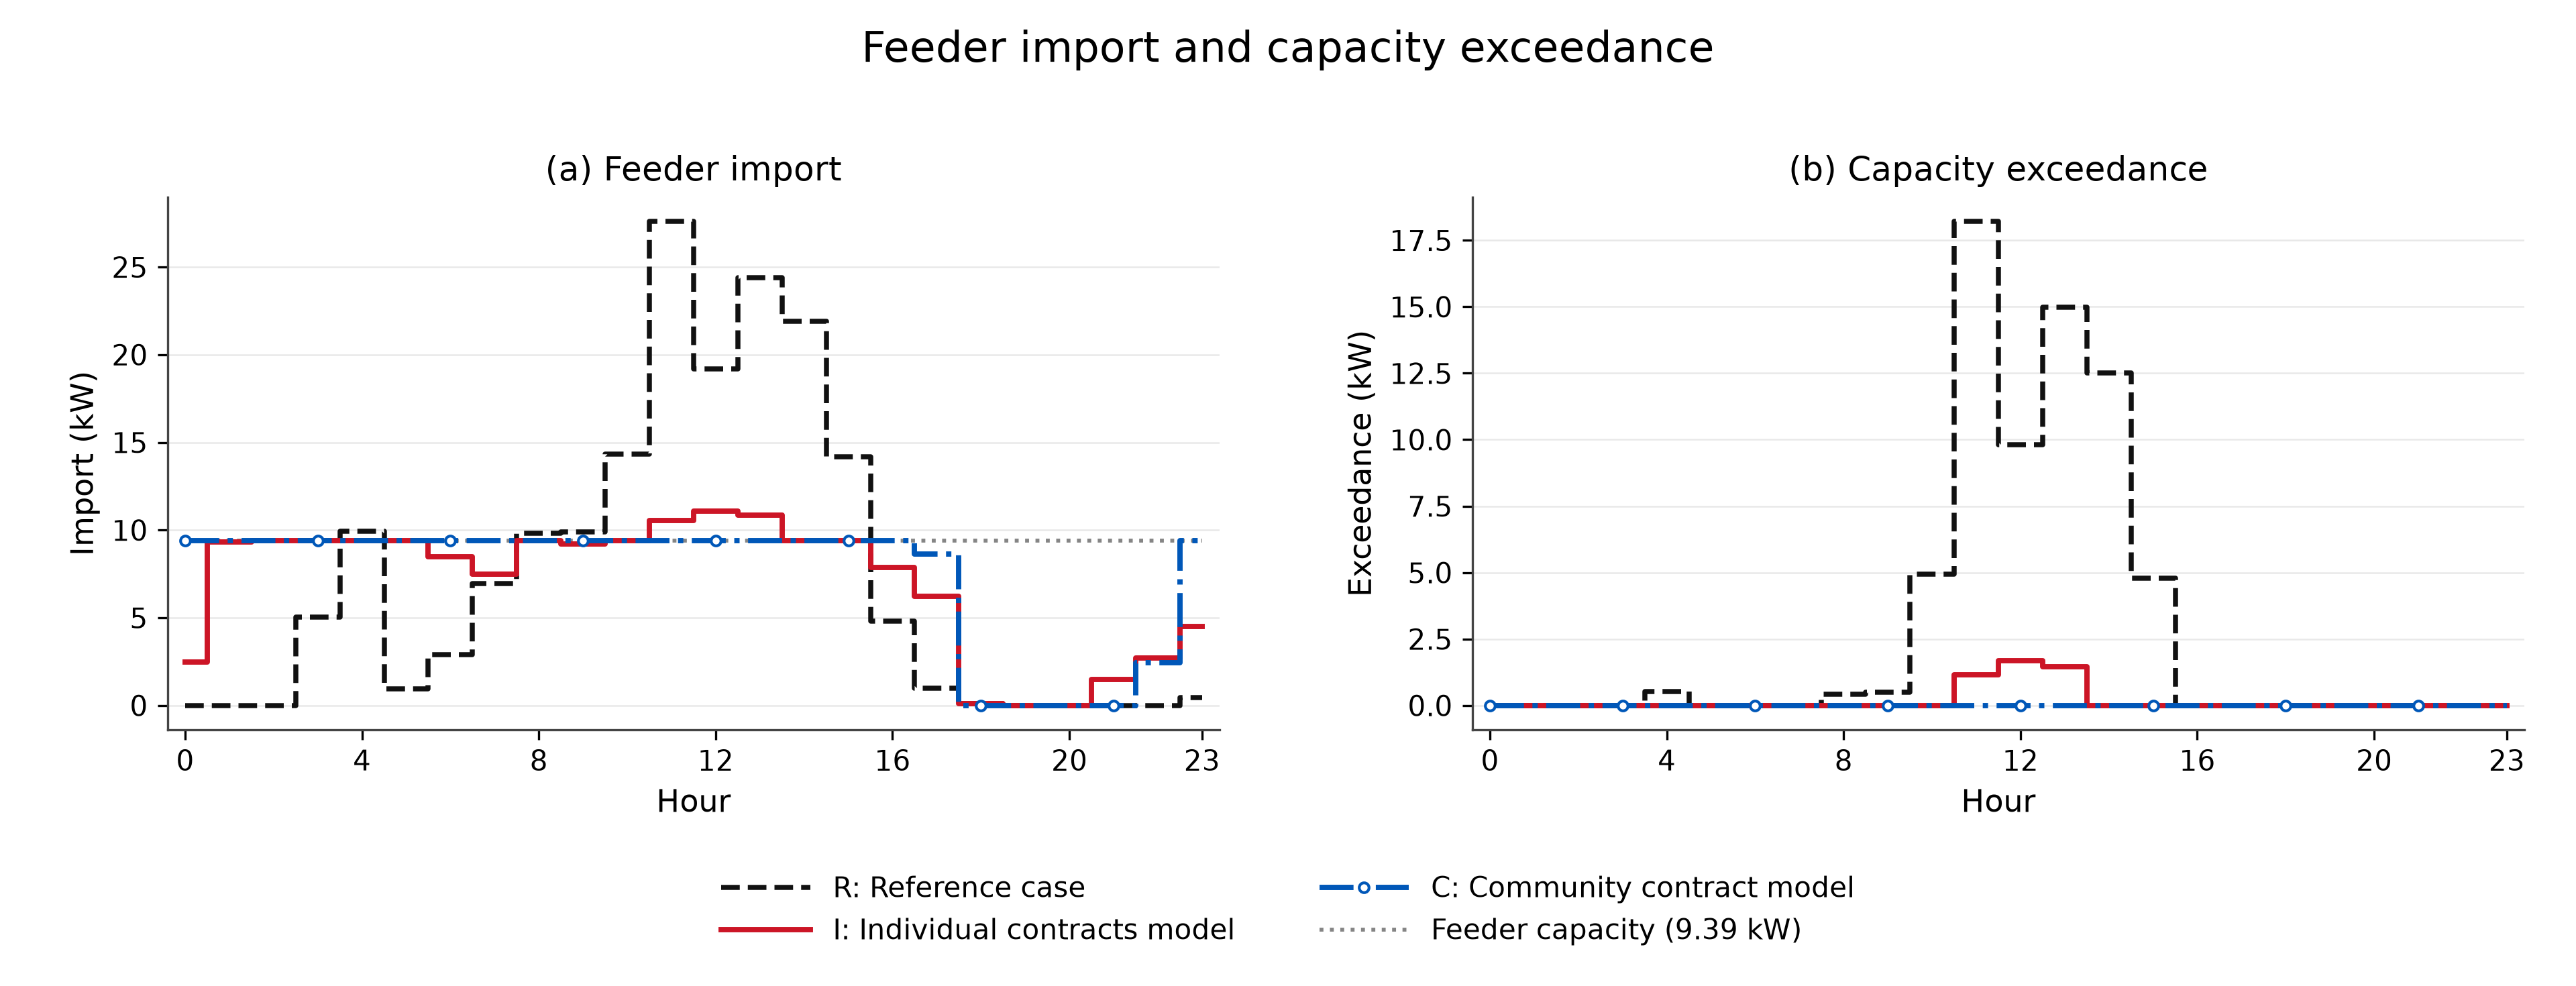

In [3]:
display(Image(filename=str(ROOT/'results/base_case/feeder_comparison.png')))

## 解释调度机制与成本

曲线检查负荷是否移出拥塞时段、电池净充电是否移到其他时段，以及 PV 利用量是否变化。共同合同减少拥塞的同时仍可能增加日进口或改变 PV 出力，因此只看总进口不能评价容量服务。成本必须区分电能、电网费、罚金、不适和 PV 成本。

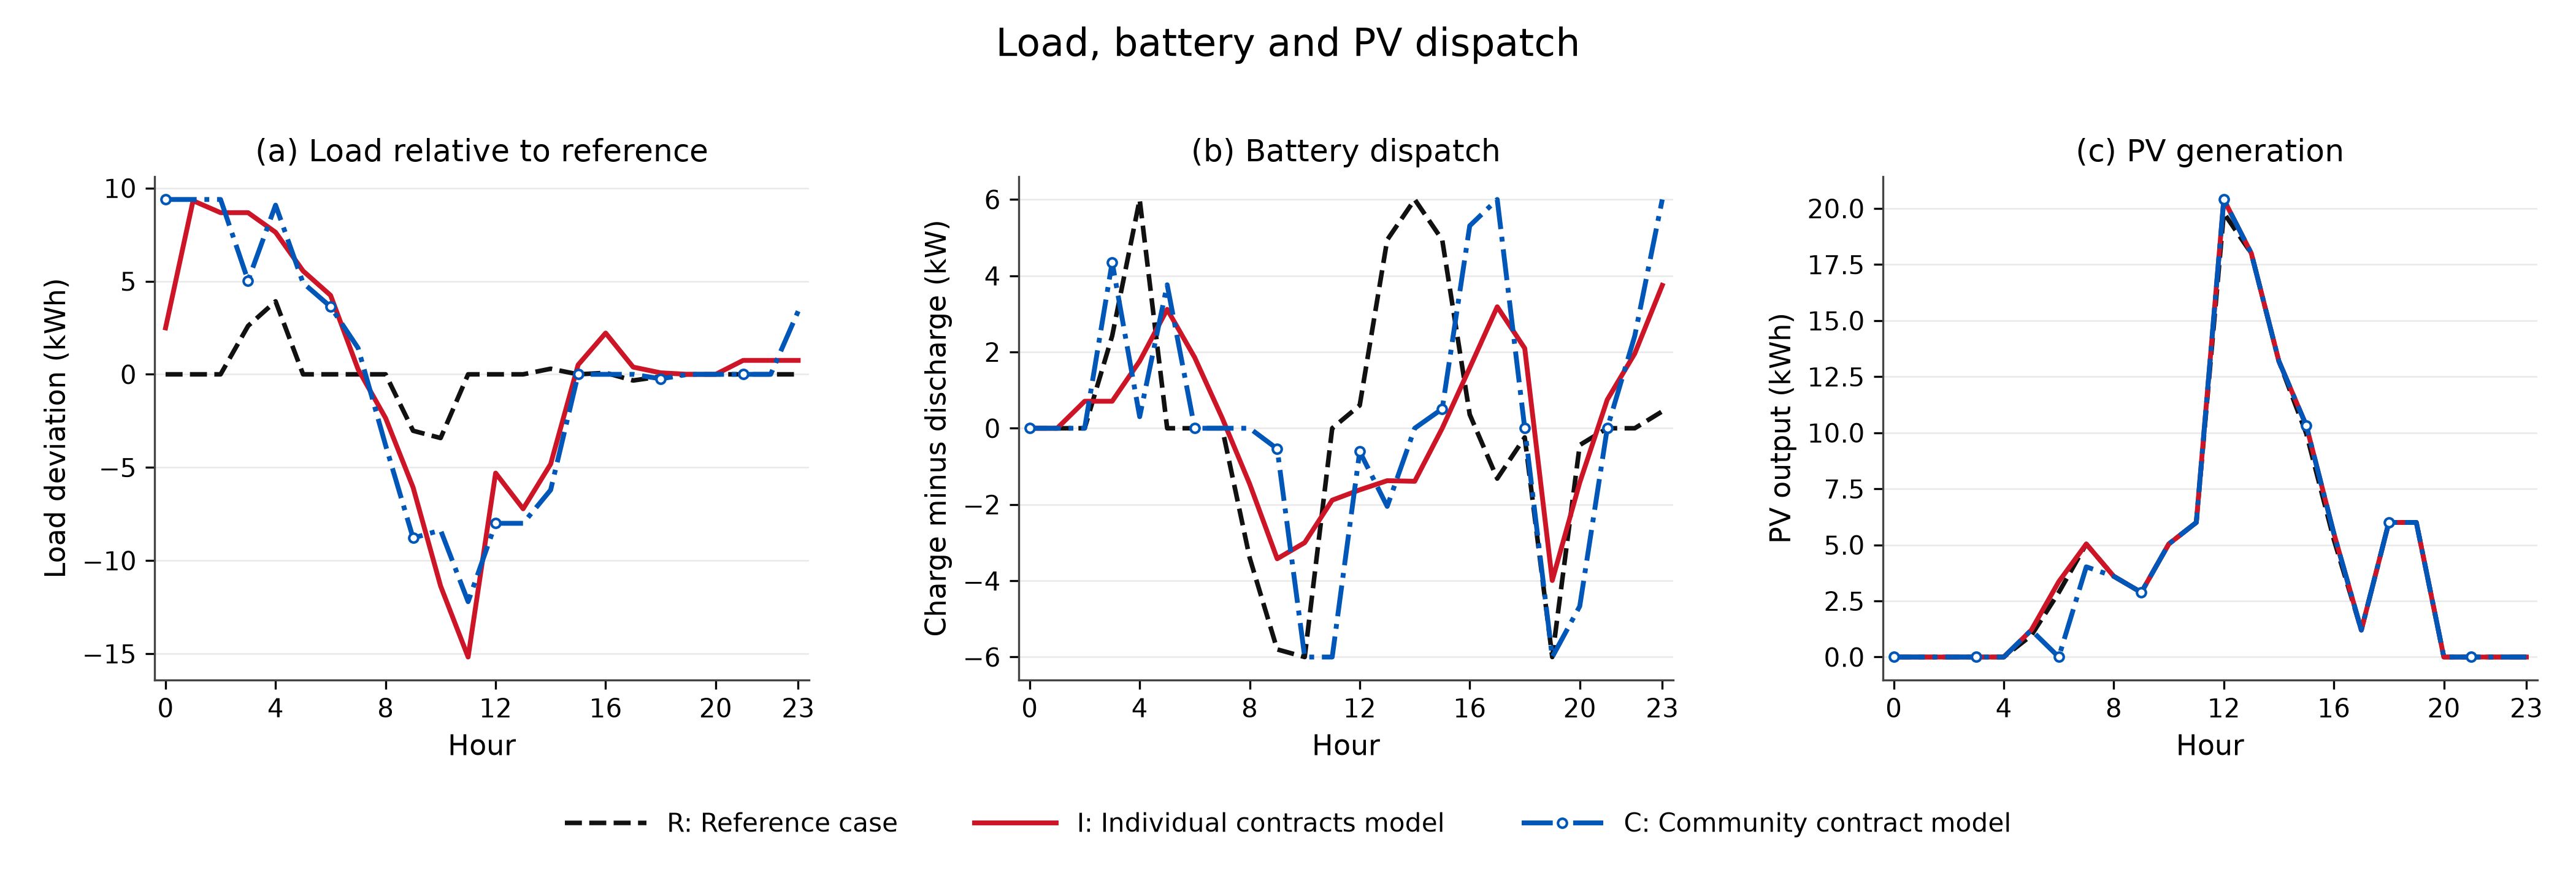

,energy_cost_DKK,tariff_cost_DKK,penalty_DKK,disutility_cost_DKK,PV_cost_DKK,daily_import_kWh,daily_export_kWh,cap_binding_hours
variant,,,,,,,,
R,151.706509,93.877186,0.000000,3.480000,149.178000,173.386371,17.960000,0
I,156.664528,22.381835,42.880393,106.801075,151.941600,167.535540,14.398922,8
C,154.295264,24.704887,0.000000,47.395000,145.767284,180.081053,21.947550,18


In [4]:
display(Image(filename=str(ROOT/'results/base_case/dispatch_response.png')))
display(table[['energy_cost_DKK','tariff_cost_DKK','penalty_DKK',
               'disutility_cost_DKK','PV_cost_DKK','daily_import_kWh',
               'daily_export_kWh','cap_binding_hours']].round(6))

## 验证：数值最优不等于模型已被证实

以下同时检查 Gurobi 原始可行性/对偶/KKT 残差、相同 LP 在 HiGHS 的最优目标、无合同极限还原 R、C 成本不高于 I、成本分解求和、基准无同时充放和同表进口出口。HiGHS 是独立求解器，但复用已组装 LP，不能排除共同的建模错误。

官方 R 的 173.4 kWh、27.6 kW、398.24 DKK 与本结果在其精度下一致。66.5 kWh 超限依赖多重最优调度；不能强制每次得到同一个调度或对偶。下面保持 R 最优目标不变寻找替代最优解，验证这一解释。另按正文逐式复算残差，并用末小时负电价反例确认程序允许末库存严格大于初始库存。

In [5]:
display(pd.DataFrame({k:r.certificate for k,r in results.items()}).T)
display(pd.DataFrame(validation['independent_solver']).T)
display(pd.DataFrame(validation['report_equation_checks']).T)
display(validation['terminal_condition_check'])
print('No-contract limit objective error (DKK):', validation['no_contract_limit_error_DKK'])
import audit_reference_ties
audit_reference_ties.main()

No-contract limit objective error (DKK): 0.0
{
  "optimal_cost_DKK": 398.2416941828257,
  "terminal": "minimum",
  "original_congested_hours": [
    4,
    8,
    9,
    10,
    11,
    12,
    13,
    14,
    15
  ],
  "tie_schedules": [
    {
      "secondary_objective": "min_import_in_original_congested_hours",
      "J_DKK": 398.2416941828252,
      "feeder_exceedance_kWh": 66.30210526320835
    },
    {
      "secondary_objective": "max_import_in_original_congested_hours",
      "J_DKK": 398.24169418282526,
      "feeder_exceedance_kWh": 66.70210526314612
    }
  ],
  "provided_exceedance_kWh": 66.5,
  "interpretation": "Recorded schedules are equally optimal; their exceedances need not be identical."
}


,primal_violation,stationarity_residual,dual_sign_violation,complementarity_residual,primal_dual_gap,reconstructed_objective_error
R,1.249001e-16,2.220446e-16,0.000000e+00,0.000000e+00,4.547474e-13,2.273737e-13
I,1.110223e-16,8.881784e-16,4.440892e-16,4.440892e-16,2.842171e-13,4.831691e-13
C,1.110223e-16,8.881784e-16,2.220446e-16,4.440892e-16,6.252776e-13,5.684342e-14


,success,objective_difference_DKK,note
R,True,0.0,"Independent solver, same assembled LP; dispatc..."
I,True,0.0,"Independent solver, same assembled LP; dispatc..."
C,True,0.0,"Independent solver, same assembled LP; dispatc..."


,load_bounds,daily_minimum,deviation_split,absolute_deviation,net_definition,battery_dynamics,asset_bounds,terminal_lower_bound,balance,cap,objective_reconstruction_DKK
R,0.0,3.552714e-15,1.276756e-15,1.276756e-15,1.110223e-16,1.249001e-16,0.0,0.0,0.000000e+00,0.0,1.136868e-13
I,0.0,3.552714e-15,0.000000e+00,0.000000e+00,1.110223e-16,1.110223e-16,0.0,0.0,0.000000e+00,0.0,5.968559e-13
C,0.0,0.000000e+00,4.440892e-16,4.440892e-16,1.110223e-16,1.110223e-16,0.0,0.0,1.776357e-15,0.0,0.000000e+00


{'case': 'single_battery_member_zero_initial_SOC_negative_last_hour_price',
 'initial_SOC_kWh': 0.0,
 'minimum_terminal_SOC_kWh': 0.7124999999999999,
 'cyclic_terminal_SOC_kWh': 0.0,
 'minimum_cost_DKK': 0.20999999999999908,
 'cyclic_cost_DKK': 3.255937499999998,
 'passed': True,
 'note': 'Demonstrates the two terminal constraints are different models.'}

## 基准结论与口试准备

- R 的峰值为 27.6 kW，9 小时超限；I 将超限显著降低但仍保留 3 小时，且整体广义成本高于 R。签约不是必然省钱。
- C 的峰值降至 9.39 kW，没有超限，成本低于 R 和 I；共享容量和电表净额计量共同发挥作用。该成本结论不代表每个成员结算后都获益。
- 日末 SOC 下限、软上限、线性不适成本、份额来源、计费解释和总成本的组成，都是需要能够解释的选择。
- 后续沿用 `CommunityModel` 的成员输入、净需求和社区平衡；Q2/Q3 还需新增价格决策、成员最优响应或情景结构，当前并未实现。

输出位于 `results/base_case/`。敏感性分析与结算分析属于 Q1 后续步骤。按组内实际使用情况补充 AI-use disclosure。